# Step 1, 2 & 3: Data Understanding, Cleaning & EDA
In this notebook, we inspect `customer_feedback.csv`, check missing values and duplicates, clean text/numerical columns, and visualize distributions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## Step 1: Understand the Dataset

In [2]:
# Load the dataset
df = pd.read_csv("../data/customer_feedback.csv")

print("Dataset Shape:", df.shape)
print("\nColumns & Data Types:")
print(df.dtypes)
df.head()

Dataset Shape: (30000, 9)

Columns & Data Types:
feedback_id             str
feedback_text           str
sentiment               str
complaint_type          str
priority                str
channel                 str
customer_type           str
order_value         float64
days_as_customer      int64
dtype: object


,feedback_id,feedback_text,sentiment,complaint_type,priority,channel,customer_type,order_value,days_as_customer
0,FB102309,Everything worked out well in the end. The bil...,Positive,Billing,Low,Phone,Loyal,131.69,469
1,FB122405,I had a good experience with the team. The sup...,Positive,Customer Service,Medium,Phone,Loyal,55.30,428
2,FB123398,"Overall, I am satisfied with the experience. T...",Positive,Technical Issue,Low,Website,New,74.98,604
3,FB125059,Everything worked out well in the end. The cou...,Positive,Delivery,Medium,Mobile App,Loyal,34.68,578
4,FB102665,I expected much better service. I received unc...,Negative,Customer Service,Low,In-Store,Returning,132.37,461


In [3]:
# Check missing values and duplicates
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# Check target class counts
print("\nSentiment Counts:\n", df["sentiment"].value_counts())
print("\nComplaint Type Counts:\n", df["complaint_type"].value_counts())
print("\nPriority Counts:\n", df["priority"].value_counts())

Missing Values:
 feedback_id         0
feedback_text       0
sentiment           0
complaint_type      0
priority            0
channel             0
customer_type       0
order_value         0
days_as_customer    0
dtype: int64

Duplicate Rows: 0

Sentiment Counts:
 sentiment
Negative    12571
Positive    10916
Neutral      6513
Name: count, dtype: int64

Complaint Type Counts:
 complaint_type
Product Quality      5964
Delivery             5401
Technical Issue      4273
Customer Service     4190
Returns & Refunds    3078
Billing              2939
Pricing              2079
Packaging            2076
Name: count, dtype: int64

Priority Counts:
 priority
Low       10200
Medium     9900
High       9900
Name: count, dtype: int64


In [4]:
# Summary statistics for numerical columns
df.describe()

,order_value,days_as_customer
count,30000.000000,30000.000000
mean,55.088379,397.061200
std,40.724470,268.330308
min,8.000000,1.000000
25%,28.610000,200.000000
50%,44.290000,339.000000
75%,68.990000,534.000000
max,836.630000,2385.000000


## Step 2: Basic Data Cleaning & Feature Inspection

In [5]:
# Remove duplicates if any exist and handle missing text safely
df = df.drop_duplicates()
df["feedback_text"] = df["feedback_text"].fillna("")

# Create simple helper columns for EDA
df["text_length"] = df["feedback_text"].apply(len)
df["word_count"] = df["feedback_text"].apply(lambda x: len(x.split()))

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (30000, 11)


## Step 3: Exploratory Data Analysis (EDA)

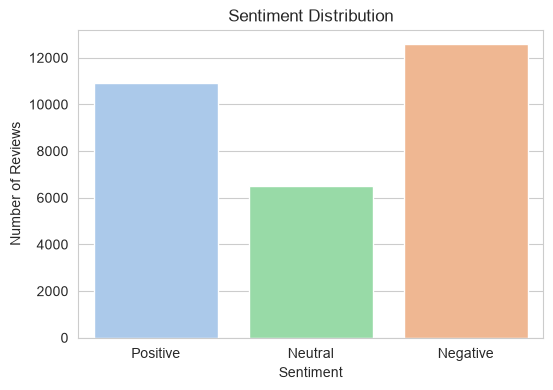

In [6]:
# 1. Sentiment Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment", order=["Positive", "Neutral", "Negative"], palette="pastel", hue="sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

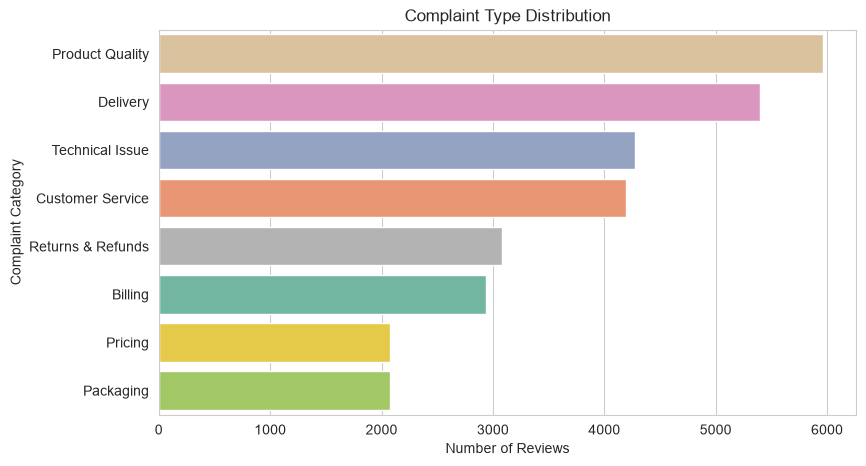

In [7]:
# 2. Complaint Category Distribution
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y="complaint_type", order=df["complaint_type"].value_counts().index, palette="Set2", hue="complaint_type")
plt.title("Complaint Type Distribution")
plt.xlabel("Number of Reviews")
plt.ylabel("Complaint Category")
plt.show()

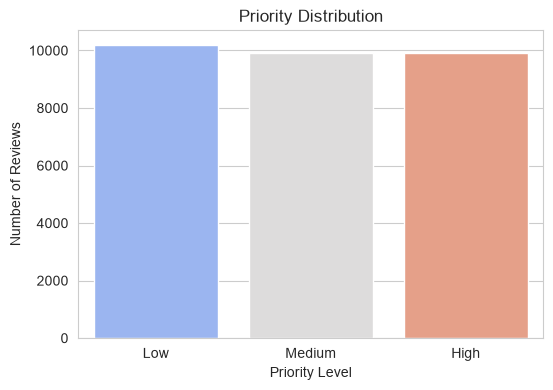

In [8]:
# 3. Priority Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="priority", order=["Low", "Medium", "High"], palette="coolwarm", hue="priority")
plt.title("Priority Distribution")
plt.xlabel("Priority Level")
plt.ylabel("Number of Reviews")
plt.show()

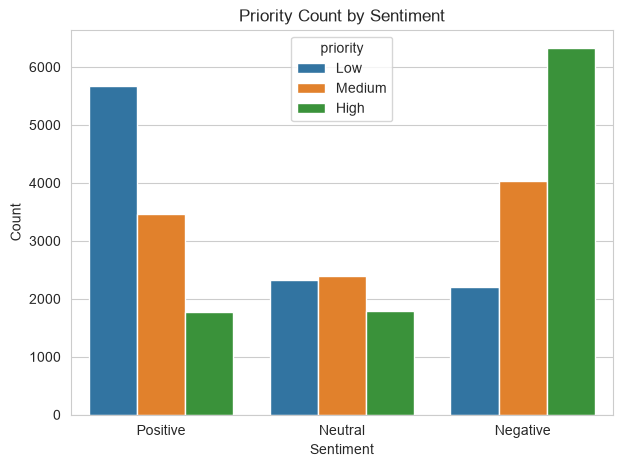

In [9]:
# 4. Relationship between Sentiment and Priority
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment", hue="priority", order=["Positive", "Neutral", "Negative"], hue_order=["Low", "Medium", "High"])
plt.title("Priority Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

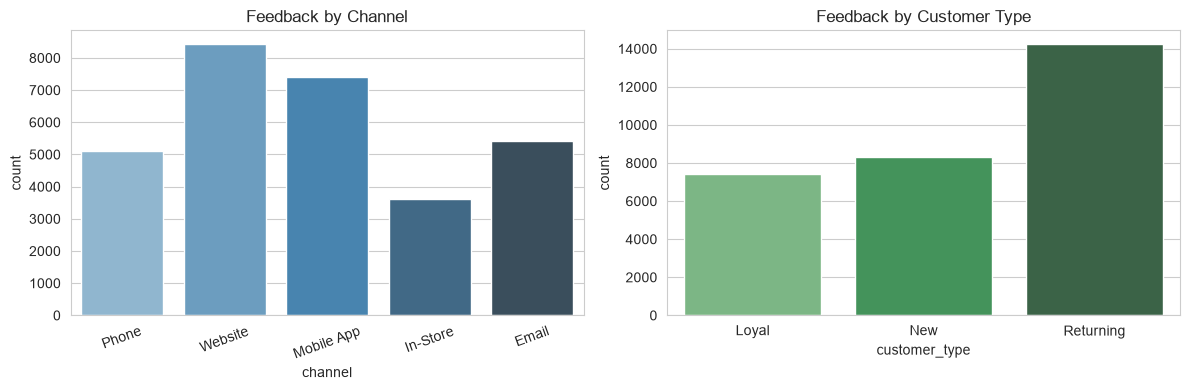

In [10]:
# 5. Feedback Channel & Customer Type Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="channel", ax=axes[0], palette="Blues_d", hue="channel")
axes[0].set_title("Feedback by Channel")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=df, x="customer_type", ax=axes[1], palette="Greens_d", hue="customer_type")
axes[1].set_title("Feedback by Customer Type")

plt.tight_layout()
plt.show()